# Task 1 missing-value EDA

คำถาม: ค่าว่างเป็นเพดานของ Task 1 (README: แถวที่ข้อมูลครบได้ AUC 0.918 ส่วนแถวที่ว่าง 8 ช่องเหลือ 0.847) มี feature ไหนที่ถ้าว่างแล้ว OOF แย่ลงจริง และเติมค่าได้จาก feature อื่นโดยไม่ใช้ label บ้าง แบบเดียวกับที่ Task 3 เจอ (V9a, +0.0026)

ตอนนี้ `pis/task1_features.py` เติมค่าอยู่แล้ว 5 ตัว: `account_age_days`, `friend_network_size`, `level_progression_speed`, `level`, `reports_received`

ข้อมูล: แถว train ที่มี label (90,816 แถว) + OOF ของโมเดลปัจจุบัน (`outputs/experiments/task1_oof.csv` จาก `Task1/eda/make_oof.py`: StratifiedKFold 3, seed 342, 12 threads เหมือนตารางใน README) ไม่ใช้ test

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import binom, norm, spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import fbeta_score, r2_score, roc_auc_score
from sklearn.model_selection import KFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA         # ../cpe342-kaggle-main, needs ROOT on sys.path
from pis.tabular import _threshold          # the pipeline's OOF threshold search for macro F2
from pis.task1_features import IMPUTED      # the 5 features the pipeline already imputes

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'

def tidy(ax, grid='y'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & check the OOF

OOF ต้องเรียงแถวเดียวกับ `train.csv` หลังตัดแถวไม่มี label (เช็ค `player_id`) และต้องได้ AUC 0.8926 / Macro F2 (threshold จูนบน OOF) 0.7807 ตาม README ก่อนจะเชื่อตัวเลขอื่นๆ

In [3]:
tr = pd.read_csv(DEFAULT_DATA / '01_binary_classification' / 'train.csv')
tr = tr.loc[tr['is_cheater'].notna()].reset_index(drop=True)  # the pipeline drops the 13,184 unlabelled rows
o = pd.read_csv('outputs/experiments/task1_oof.csv')           # current model, 3-fold OOF
assert (tr['player_id'].to_numpy() == o['player_id'].to_numpy()).all(), 'OOF row order differs from train.csv'
assert (tr['is_cheater'].to_numpy() == o['target'].to_numpy()).all()

feats = [c for c in tr.columns if c not in ('player_id', 'is_cheater')]  # the 31 raw features
y = o['target'].to_numpy().astype(int)
p = o['probability_1'].to_numpy()
threshold, f2_all = _threshold(y, p)   # same threshold the pipeline picks
pred = (p >= threshold).astype(int)
auc_all = roc_auc_score(y, p)
print(f"rows {len(tr):,} | cheaters {y.mean():.1%} | OOF AUC {auc_all:.4f} | macro F2 {f2_all:.4f} at threshold {threshold:.3f}")
assert abs(auc_all - 0.8926) < 5e-4 and abs(f2_all - 0.7807) < 5e-4, 'OOF does not reproduce the README (0.8926 / 0.7807)'


def macro_f2(tp, fp, fn, tn):
    # Macro F2 from confusion counts (works on arrays too): mean of F2 for class 1 and for class 0.
    pos = 5 * tp / (5 * tp + 4 * fn + fp)
    neg = 5 * tn / (5 * tn + 4 * fp + fn)
    return (pos + neg) / 2


def scores(m):
    # AUC and macro F2 at the current threshold on the rows in boolean mask m.
    t, q = y[m], pred[m]
    tp, fp = np.sum((t == 1) & (q == 1)), np.sum((t == 0) & (q == 1))
    fn, tn = np.sum((t == 1) & (q == 0)), np.sum((t == 0) & (q == 0))
    return roc_auc_score(t, p[m]), macro_f2(tp, fp, fn, tn)


assert abs(scores(np.ones(len(y), bool))[1] - fbeta_score(y, pred, beta=2, average='macro')) < 1e-12

rows 90,816 | cheaters 34.9% | OOF AUC 0.8922 | macro F2 0.7808 at threshold 0.380


**NOTE:**


AUC 0.8922 / macro F2 0.7808 vs README 0.8926 / 0.7807. The gap is not in this script: the README's own command (`python Task1/experiments.py ../cpe342-kaggle-main margins+impute`) gives the same AUC 0.8922 (tuned F2 0.7805) on this laptop, and its baseline row shifts the same way (0.8881 vs 0.8883). 12 threads or all 16 give the same AUC. The README numbers come from another environment. Tuned F2 matches to 0.0001, so this OOF is used as is.

## 1. Missingness overview

ค่าว่างต่อ feature (สีส้ม = 5 ตัวที่ pipeline เติมค่าอยู่แล้ว) และจำนวนช่องที่ว่างต่อแถว พร้อม AUC / Macro F2 ของ OOF ในแต่ละกลุ่ม

share missing per feature: min 0.6%, median 9.6%, max 24.3% | rows with no missing value: 1.8%, mean missing per row 3.71


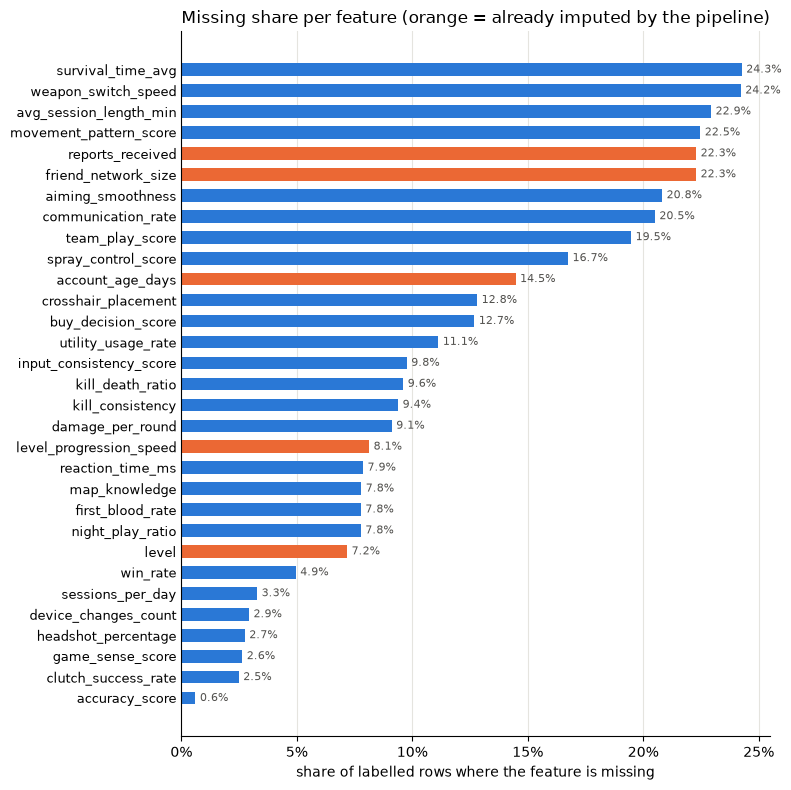

In [4]:
miss = tr[feats].isna()
share_missing = miss.mean().sort_values()
n_missing = miss.sum(axis=1).to_numpy()
print(f"share missing per feature: min {share_missing.min():.1%}, median {share_missing.median():.1%}, max {share_missing.max():.1%} | "
      f"rows with no missing value: {(n_missing == 0).mean():.1%}, mean missing per row {n_missing.mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(share_missing.index, share_missing.values, height=0.6,
        color=[ORANGE if c in IMPUTED else BLUE for c in share_missing.index])
for name, v in share_missing.items():
    ax.text(v + 0.002, name, f"{v:.1%}", va='center', fontsize=8, color=INK)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('share of labelled rows where the feature is missing')
ax.set_title('Missing share per feature (orange = already imputed by the pipeline)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

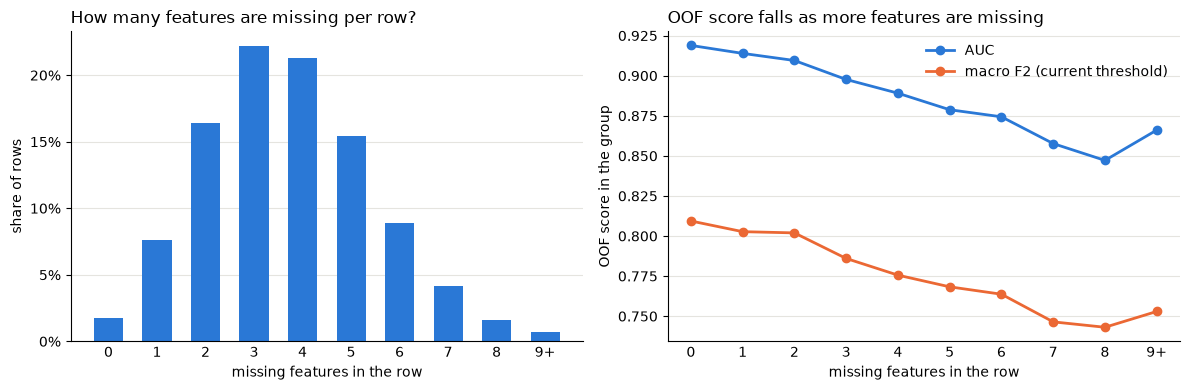

,rows,row_share,cheater_share,AUC,macro F2
missing features,,,,,
0,"1,607",1.8%,35.7%,0.9189,0.8094
1,"6,909",7.6%,34.5%,0.9139,0.8027
2,"14,880",16.4%,34.8%,0.9095,0.8020
3,"20,149",22.2%,35.0%,0.8976,0.7860
4,"19,335",21.3%,34.8%,0.8891,0.7756
5,"13,985",15.4%,34.5%,0.8788,0.7683
6,"8,080",8.9%,35.6%,0.8744,0.7637
7,"3,771",4.2%,36.1%,0.8577,0.7465
8,"1,434",1.6%,35.1%,0.8472,0.7431


In [5]:
group = np.minimum(n_missing, 9)
rows = []
for g in range(10):
    m = group == g
    auc, f2 = scores(m)
    rows.append({'missing features': '9+' if g == 9 else str(g), 'rows': int(m.sum()), 'row_share': m.mean(),
                 'cheater_share': y[m].mean(), 'AUC': auc, 'macro F2': f2})
by_count = pd.DataFrame(rows).set_index('missing features')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(by_count.index, by_count['row_share'], width=0.6, color=BLUE)
a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a1.set_xlabel('missing features in the row'); a1.set_ylabel('share of rows')
a1.set_title('How many features are missing per row?', loc='left')
a1.tick_params(axis='x', length=0); tidy(a1)
a2.plot(by_count.index, by_count['AUC'], marker='o', color=BLUE, linewidth=2, label='AUC')
a2.plot(by_count.index, by_count['macro F2'], marker='o', color=ORANGE, linewidth=2, label='macro F2 (current threshold)')
a2.set_xlabel('missing features in the row'); a2.set_ylabel('OOF score in the group')
a2.set_title('OOF score falls as more features are missing', loc='left')
a2.legend(frameon=False); a2.tick_params(axis='x', length=0); tidy(a2)
plt.tight_layout()
plt.show()

(by_count.style
    .format({'rows': '{:,}', 'row_share': '{:.1%}', 'cheater_share': '{:.1%}', 'AUC': '{:.4f}', 'macro F2': '{:.4f}'})
    .set_caption('OOF score by number of missing features per row'))

**NOTE:**


Only 1.8% of rows are complete. On average 3.7 of the 31 features are missing per row, and the share per feature ranges from 0.6% to 24%. The score falls steadily with each missing feature: from 0 to 8 missing, AUC goes 0.919 → 0.847 and macro F2 0.809 → 0.743 (9+ is only 666 rows). The cheater share is the same in every group (34.5–36.1%), so the drop is lost information, not harder rows.

## 2. Score by feature: missing vs present (+ random-group null)

แต่ละ feature แบ่งแถวเป็น "ว่าง" กับ "มีค่า" แล้วเทียบ AUC และ Macro F2 (threshold เดิม) ของ OOF รวมทั้ง % คนโกงในสองกลุ่ม (ดูว่าการว่างบอก label หรือไม่)

กลุ่มที่ว่างมีขนาดต่างกัน (0.6% ถึง 24% ของแถว) คะแนนกลุ่มเล็กจึงแกว่งได้มาก เลยเทียบกับกลุ่มที่สุ่มมาจากทุกแถวด้วยขนาดเท่ากัน 2,000 ครั้ง:
- `z` = (คะแนนกลุ่มที่ว่าง − ค่าเฉลี่ยของกลุ่มสุ่ม) / SD ของกลุ่มสุ่ม: ติดลบ = แย่กว่ากลุ่มสุ่ม
- `p` = two-sided p-value จาก 2,000 ครั้ง (ต่ำสุดที่วัดได้ ≈ 0.001)
- ทดสอบ 31 feature พร้อมกัน จึงใช้ Bonferroni: significant เมื่อ p < 0.05 / 31 = 0.0016 (คือไม่มีกลุ่มสุ่มไหนแย่ขนาดนั้นเลย)
- AUC เป็นตัวทดสอบหลัก เพราะไม่ขึ้นกับสัดส่วนคนโกงในกลุ่ม ส่วน F2 ขึ้นกับสัดส่วนนั้นด้วย

In [6]:
rows = []
for c in feats:
    m = miss[c].to_numpy()
    auc_m, f2_m = scores(m)
    auc_p, f2_p = scores(~m)
    rows.append({'feature': c, 'rows_missing': int(m.sum()), 'row_share': m.mean(),
                 'cheat_missing': y[m].mean(), 'cheat_present': y[~m].mean(),
                 'auc_missing': auc_m, 'auc_present': auc_p, 'f2_missing': f2_m, 'f2_present': f2_p})
by_feat = pd.DataFrame(rows).set_index('feature')
by_feat['auc_gap'] = by_feat['auc_missing'] - by_feat['auc_present']
by_feat['f2_gap'] = by_feat['f2_missing'] - by_feat['f2_present']

# Null: random groups of the same size. Rows are sorted by p once, so a group's AUC comes from rank sums (fast).
D = 2000
rng = np.random.default_rng(342)
order = np.argsort(p, kind='stable')
ys, preds_s = y[order], pred[order]
sizes = by_feat['rows_missing'].to_numpy()
null_auc = np.empty((D, len(feats)))
null_f2 = np.empty((D, len(feats)))
for d in range(D):
    rank = rng.permutation(len(y))  # one random ordering per draw; a group of size n is its first n rows
    for j, n in enumerate(sizes):
        m = rank < n
        r = np.cumsum(m)            # 1-based rank of each chosen row inside the group
        pos = m & (ys == 1)
        n1 = pos.sum(); n0 = n - n1
        null_auc[d, j] = (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
        tp = np.sum(pos & (preds_s == 1)); fp = np.sum(m & (ys == 0) & (preds_s == 1))
        null_f2[d, j] = macro_f2(tp, fp, n1 - tp, n0 - fp)
    if d == 0:  # check the fast AUC against sklearn on the first draw
        chosen = np.zeros(len(y), bool); chosen[order[rank < sizes[0]]] = True
        assert abs(null_auc[0, 0] - roc_auc_score(y[chosen], p[chosen])) < 1e-6


def null_test(obs, null):
    low = (1 + (null <= obs).sum(0)) / (D + 1)
    high = (1 + (null >= obs).sum(0)) / (D + 1)
    return np.minimum(1, 2 * np.minimum(low, high)), (obs - null.mean(0)) / null.std(0)


by_feat['p_auc'], by_feat['z_auc'] = null_test(by_feat['auc_missing'].to_numpy(), null_auc)
by_feat['p_f2'], by_feat['z_f2'] = null_test(by_feat['f2_missing'].to_numpy(), null_f2)
BONF = 0.05 / len(feats)
by_feat['sig_auc'] = np.where(by_feat['p_auc'] < BONF, np.where(by_feat['z_auc'] < 0, 'worse', 'better'), '')
by_feat['sig_f2'] = np.where(by_feat['p_f2'] < BONF, np.where(by_feat['z_f2'] < 0, 'worse', 'better'), '')
by_feat = by_feat.sort_values('z_auc')

k95 = int(binom.ppf(0.95, len(feats), 0.05))
print(f"p < 0.05 (no correction): AUC {(by_feat['p_auc'] < 0.05).sum()}, F2 {(by_feat['p_f2'] < 0.05).sum()} of {len(feats)} features | "
      f"chance alone: {len(feats) * 0.05:.1f} expected, up to {k95} in 95% of cases")
print(f"Bonferroni p < {BONF:.4f}: AUC worse {(by_feat['sig_auc'] == 'worse').sum()}, better {(by_feat['sig_auc'] == 'better').sum()} | "
      f"F2 worse {(by_feat['sig_f2'] == 'worse').sum()}, better {(by_feat['sig_f2'] == 'better').sum()} (chance alone: {len(feats) * BONF:.2f})")

(by_feat.drop(columns=['auc_present', 'f2_present']).style
    .format({'rows_missing': '{:,}', 'row_share': '{:.1%}', 'cheat_missing': '{:.1%}', 'cheat_present': '{:.1%}',
             'auc_missing': '{:.4f}', 'f2_missing': '{:.4f}', 'auc_gap': '{:+.4f}', 'f2_gap': '{:+.4f}',
             'p_auc': '{:.4f}', 'z_auc': '{:+.1f}', 'p_f2': '{:.4f}', 'z_f2': '{:+.1f}'})
    .bar(subset='z_auc', align=0, color=[RED, BLUE])
    .set_caption(f'OOF score where each feature is missing vs present (AUC present ≈ {by_feat.auc_present.median():.4f}), sorted by z (AUC)'))

p < 0.05 (no correction): AUC 6, F2 6 of 31 features | chance alone: 1.6 expected, up to 4 in 95% of cases
Bonferroni p < 0.0016: AUC worse 4, better 0 | F2 worse 4, better 0 (chance alone: 0.05)


,rows_missing,row_share,cheat_missing,cheat_present,auc_missing,f2_missing,auc_gap,f2_gap,p_auc,z_auc,p_f2,z_f2,sig_auc,sig_f2
feature,,,,,,,,,,,,,,
reports_received,"20,242",22.3%,34.8%,35.0%,0.8538,0.7411,-0.0482,-0.0509,0.0010,-20.6,0.0010,-15.2,worse,worse
friend_network_size,"20,240",22.3%,34.8%,35.0%,0.8551,0.7456,-0.0467,-0.0453,0.0010,-19.9,0.0010,-13.5,worse,worse
account_age_days,"13,141",14.5%,34.7%,35.0%,0.8584,0.7500,-0.0390,-0.0359,0.0010,-13.9,0.0010,-9.1,worse,worse
crosshair_placement,"11,629",12.8%,35.1%,34.9%,0.8600,0.7491,-0.0366,-0.0364,0.0010,-12.2,0.0010,-8.7,worse,worse
level,"6,515",7.2%,34.9%,34.9%,0.8825,0.7703,-0.0104,-0.0113,0.0070,-2.7,0.0500,-2.1,,
game_sense_score,"2,393",2.6%,33.9%,35.0%,0.8759,0.7572,-0.0167,-0.0242,0.0120,-2.6,0.0080,-2.7,,
sessions_per_day,"2,976",3.3%,34.6%,34.9%,0.8833,0.7752,-0.0092,-0.0057,0.1249,-1.6,0.4988,-0.7,,
survival_time_avg,"22,034",24.3%,35.1%,34.9%,0.8901,0.7797,-0.0028,-0.0014,0.2199,-1.2,0.6847,-0.4,,
kill_death_ratio,"8,723",9.6%,34.7%,35.0%,0.8887,0.7763,-0.0039,-0.0050,0.2679,-1.1,0.3008,-1.0,,


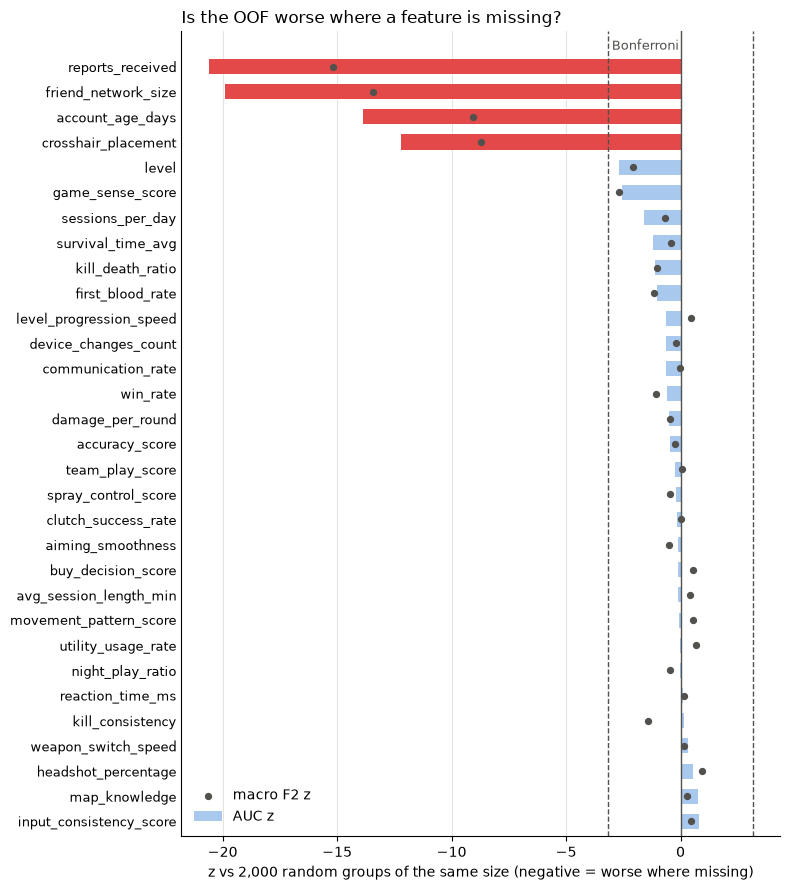

In [7]:
zz = by_feat.sort_values('z_auc', ascending=False)  # barh draws bottom-up, so the most negative ends on top
z_bonf = norm.ppf(1 - BONF / 2)
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(zz.index, zz['z_auc'], height=0.6, color=[RED if s == 'worse' else BLUE if s == 'better' else '#a9c8ee' for s in zz['sig_auc']],
        label='AUC z')
ax.scatter(zz['z_f2'], zz.index, color=INK, s=18, zorder=3, label='macro F2 z')
for v in (-z_bonf, z_bonf):
    ax.axvline(v, color=INK, linestyle='--', linewidth=1)
ax.axvline(0, color=INK, linewidth=1)
ax.set_ylim(-0.6, len(zz) + 0.4)
ax.text(-z_bonf + 0.15, len(zz) - 0.45, 'Bonferroni', ha='left', va='bottom', fontsize=9, color=INK)
ax.set_xlabel('z vs 2,000 random groups of the same size (negative = worse where missing)')
ax.set_title('Is the OOF worse where a feature is missing?', loc='left')
ax.legend(frameon=False, loc='lower left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


Only 4 of 31 features have a real gap, and it is large (z −12 to −21, no random group came close): `reports_received`, `friend_network_size`, `account_age_days`, `crosshair_placement`. Their missing rows score AUC 0.854–0.860 against 0.892 where present. All 4 are range-rule features, whose value can settle the label when present.

Without correction 6 features reach p < 0.05, while chance alone gives up to 4, so `level` (p 0.007) and `game_sense_score` (p 0.012) are borderline and not counted. The other 25 features cost nothing when missing, including `survival_time_avg` and `weapon_switch_speed`, which are missing in 24% of rows. The cheater share is the same whether a feature is missing or not (34–36%), so the fact that a value is missing carries no label information.

## 3. Can each feature be imputed? (label-free)

แต่ละ feature: เทรน HistGradientBoosting 3-fold บนแถวที่มีค่า ใช้ feature อื่น 30 ตัวเท่านั้น (**ไม่ใช้** `is_cheater` และไม่ใช้แถว test) แล้ววัด R² และ Spearman ระหว่างค่าที่ทายกับค่าจริงแบบ out-of-fold ทุก feature เป็นตัวเลข (ไม่มี feature binary) จึงใช้ R² ทั้งหมด

feature ที่ช่วยทายวัดด้วย permutation importance (R² ที่หายไปเมื่อสลับค่า feature นั้น, 5,000 แถวของ fold สุดท้าย)

เกณฑ์ "เติมค่าได้" = R² > 0.3 (เกณฑ์เดียวกับ Task 3) ส่วน `imputed` = pipeline เติมค่าอยู่แล้ว (ใช้ `max_iter=200` ต่างจากที่นี่เล็กน้อย)

In [8]:
impute_rows = []
for f in feats:
    present = tr[f].notna()
    X = tr.loc[present, [c for c in feats if c != f]]  # the other 30 features only, never the label
    t = tr.loc[present, f]
    pr = np.zeros(len(t))
    for a, b in KFold(3, shuffle=True, random_state=342).split(X):
        model = HistGradientBoostingRegressor(random_state=342).fit(X.iloc[a], t.iloc[a])
        pr[b] = model.predict(X.iloc[b])
    pi = permutation_importance(model, X.iloc[b][:5000], t.iloc[b][:5000], n_repeats=3, random_state=342, scoring='r2')
    top = pd.Series(pi.importances_mean, X.columns).sort_values(ascending=False).head(3)
    impute_rows.append({'feature': f, 'rows used': len(t), 'R²': r2_score(t, pr), 'Spearman': spearmanr(t, pr)[0],
                        'imputed': 'yes' if f in IMPUTED else '',
                        'top predictors (R² drop)': ', '.join(f"{k} {v:.2f}" for k, v in top.items())})
imputation = pd.DataFrame(impute_rows).set_index('feature').sort_values('R²', ascending=False)
print(f"features with R² > 0.3: {(imputation['R²'] > 0.3).sum()} of {len(feats)}")
(imputation.style
    .format({'rows used': '{:,}', 'R²': '{:.3f}', 'Spearman': '{:.3f}'})
    .bar(subset='R²', color='#86b6ef', vmin=0, vmax=1)
    .set_caption('Label-free imputation, 3-fold out-of-fold on rows where the feature is present'))

features with R² > 0.3: 3 of 31


,rows used,R²,Spearman,imputed,top predictors (R² drop)
feature,,,,,
account_age_days,"77,675",0.709,0.848,yes,"level_progression_speed 0.99, friend_network_size 0.18, level 0.12"
level_progression_speed,"83,437",0.629,0.775,yes,"account_age_days 1.38, level 0.13, friend_network_size 0.03"
friend_network_size,"70,576",0.498,0.637,yes,"account_age_days 0.56, level_progression_speed 0.28, reports_received 0.06"
level,"84,301",0.286,0.512,yes,"level_progression_speed 1.02, account_age_days 0.60, friend_network_size 0.02"
reaction_time_ms,"83,675",0.235,0.404,,"input_consistency_score 0.13, aiming_smoothness 0.11, first_blood_rate 0.05"
spray_control_score,"75,612",0.209,0.404,,"aiming_smoothness 0.17, movement_pattern_score 0.11, reaction_time_ms 0.04"
aiming_smoothness,"71,914",0.208,0.383,,"spray_control_score 0.17, reaction_time_ms 0.13, input_consistency_score 0.01"
reports_received,"70,574",0.205,0.338,yes,"friend_network_size 0.19, account_age_days 0.12, crosshair_placement 0.03"
kill_death_ratio,"82,093",0.119,0.299,,"headshot_percentage 0.06, win_rate 0.04, accuracy_score 0.03"


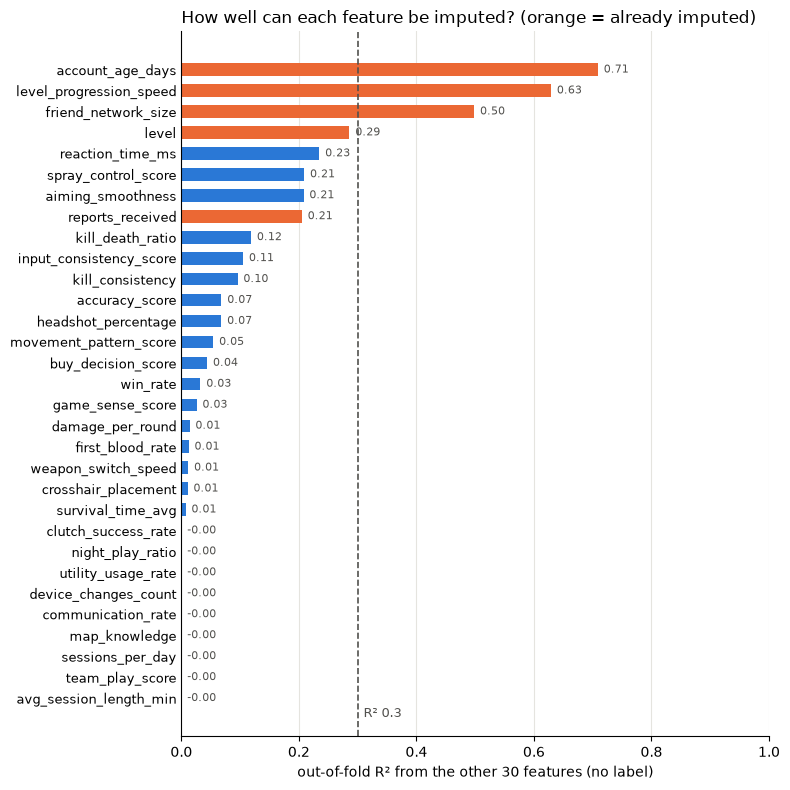

In [9]:
r2 = imputation['R²'].sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(r2.index, r2.values.clip(min=0), height=0.6, color=[ORANGE if c in IMPUTED else BLUE for c in r2.index])
ax.axvline(0.3, color=INK, linestyle='--', linewidth=1.2)
ax.text(0.31, -0.9, 'R² 0.3', fontsize=9, color=INK)
for name, v in r2.items():
    ax.text(max(v, 0) + 0.01, name, f"{v:.2f}", va='center', fontsize=8, color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel('out-of-fold R² from the other 30 features (no label)')
ax.set_title('How well can each feature be imputed? (orange = already imputed)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


Only one block is imputable: the account history. `account_age_days` R² 0.71, `level_progression_speed` 0.63 and `friend_network_size` 0.50 are predicted mostly from each other, and all three are already imputed. `level` (0.29) and `reports_received` (0.21) are below the 0.3 bar, and the pipeline imputes them too.

A second weak block, `reaction_time_ms` / `spray_control_score` / `aiming_smoothness` (R² 0.21–0.24), has no score gap. 17 features have R² < 0.05, and 10 of them are at 0 (nothing in the other features predicts them). `crosshair_placement`, the only significant feature that is not imputed, has R² 0.01.

## 4. Correlation blocks

Spearman ระหว่าง feature ทุกคู่ (pairwise บนแถวที่มีค่าทั้งคู่) เรียงด้วย hierarchical clustering (average linkage, ระยะ = 1 − |ρ|) feature ที่สัมพันธ์กันจะอยู่ติดกันเป็นบล็อก ถ้า feature อยู่ในบล็อกก็เติมค่าได้ ถ้าอยู่เดี่ยวๆ ก็เติมไม่ได้

ต่อด้วยคู่ที่สัมพันธ์กันมากที่สุด แยกตามคลาส (README: ในกลุ่มผู้เล่นปกติบางคู่สัมพันธ์กัน แต่ในกลุ่มคนโกงไม่)

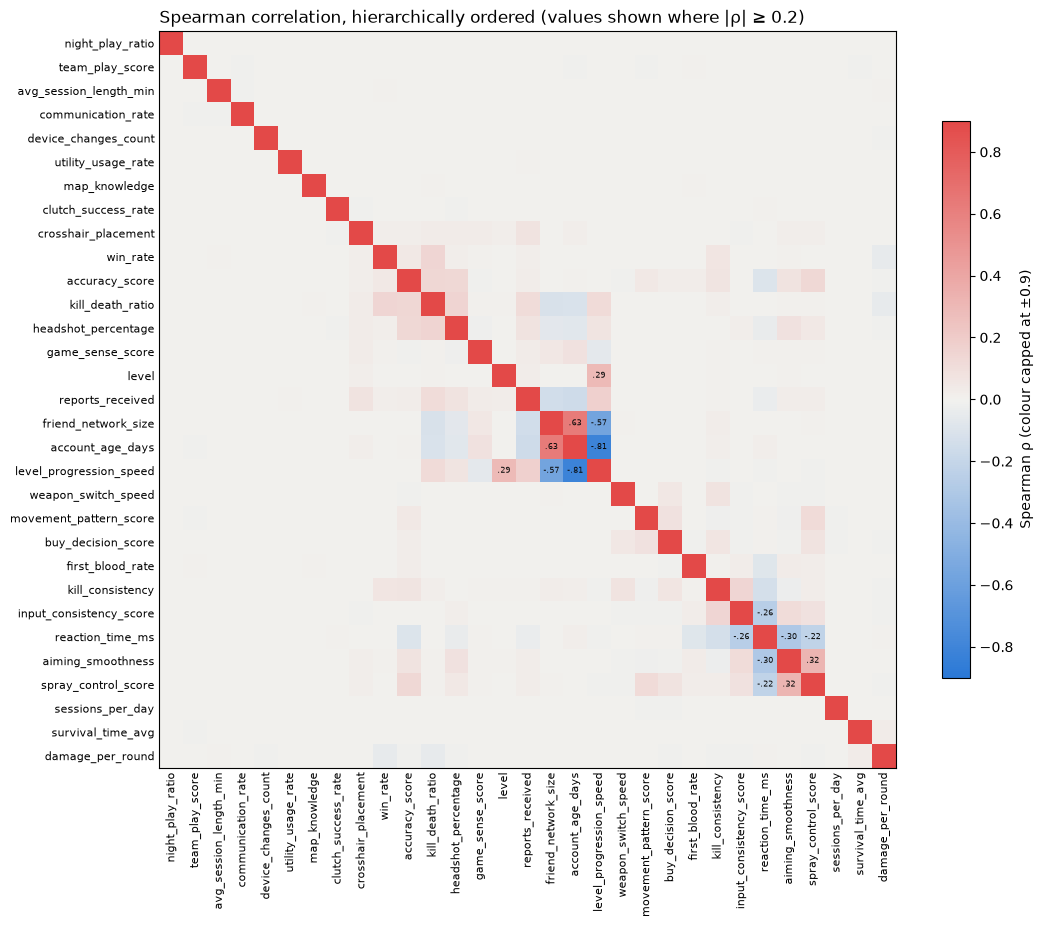

max |ρ| between two different features: 0.814 | pairs with |ρ| ≥ 0.2: 8 of 465
blocks with more than one feature (average-linkage, cut at 1 − |ρ| = 0.8):
   account_age_days, level_progression_speed, friend_network_size
   reaction_time_ms, aiming_smoothness, spray_control_score


In [10]:
rho = tr[feats].corr(method='spearman')
Z = linkage(squareform(1 - rho.abs().to_numpy(), checks=False), 'average')
ordered = rho.index[leaves_list(Z)]
R = rho.loc[ordered, ordered]
off = np.abs(R.to_numpy()[~np.eye(len(R), dtype=bool)])
vmax = np.ceil(off.max() * 10) / 10

cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f2f1ee', RED])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(R.to_numpy(), cmap=cmap, vmin=-vmax, vmax=vmax)
for i in range(len(R)):
    for j in range(len(R)):
        v = R.iat[i, j]
        if i != j and abs(v) >= 0.2:
            ax.text(j, i, f"{v:.2f}".replace('0.', '.'), ha='center', va='center', fontsize=6, color='#0b0b0b')
ax.set_xticks(range(len(R)), R.index, rotation=90, fontsize=8)
ax.set_yticks(range(len(R)), R.index, fontsize=8)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman ρ (colour capped at ±%.1f)' % vmax)
ax.set_title('Spearman correlation, hierarchically ordered (values shown where |ρ| ≥ 0.2)', loc='left')
plt.tight_layout()
plt.show()

blocks = pd.Series(fcluster(Z, t=0.8, criterion='distance'), rho.index)  # same block if linked at |ρ| ≥ ~0.2
blocks = blocks.groupby(blocks).apply(lambda s: list(s.index))
print(f"max |ρ| between two different features: {off.max():.3f} | pairs with |ρ| ≥ 0.2: {int((off >= 0.2).sum() / 2)} of {len(feats) * (len(feats) - 1) // 2}")
print('blocks with more than one feature (average-linkage, cut at 1 − |ρ| = 0.8):')
for b in blocks[blocks.map(len) > 1]:
    print('  ', ', '.join(b))

In [11]:
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename('all rows').to_frame()
pairs = pairs.reindex(pairs['all rows'].abs().sort_values(ascending=False).index).head(12)
for k, name in ((0, 'legit only'), (1, 'cheaters only')):
    r_k = tr.loc[y == k, feats].corr(method='spearman')
    pairs[name] = [r_k.loc[a, b] for a, b in pairs.index]
pairs.style.format('{:+.3f}').set_caption('Strongest pairs: Spearman ρ over all rows and inside each class')

**NOTE:**


There are two blocks: account history (age, progression speed, friends; |ρ| 0.57–0.81) and aim mechanics (reaction time, aiming smoothness, spray control, input consistency; |ρ| 0.22–0.32). Only 8 of 465 pairs reach |ρ| 0.2; everything else is independent. The blocks look the same in both classes. The only pairs that depend on the class are `reports_received` with age and progression speed (ρ ≈ ∓0.28 for legit players, 0.00 for cheaters), as the README found.

## 5. Shortlist & oracle

**Shortlist** = gap ที่ significant (AUC แย่กว่ากลุ่มสุ่ม, Bonferroni) **และ** เติมค่าได้ (R² > 0.3) **และ** ยังไม่ได้เติมค่าใน pipeline

**Oracle** (ขอบบน): แถวที่ feature นั้นว่างให้ได้คุณภาพเท่ากลุ่มที่มีค่า ทำโดยแทนความน่าจะเป็น OOF ของแถวที่ว่างด้วยค่าที่สุ่มจากแถวที่มีค่า**ในคลาสเดียวกัน** (คนโกงสุ่มจากคนโกง ผู้เล่นปกติสุ่มจากผู้เล่นปกติ) แล้ววัด AUC และ Macro F2 ทั้งหมดใหม่ (เฉลี่ย 10 รอบ) การเติมค่าจริงทำได้ไม่ถึงขอบบนนี้ เพราะค่าที่เติมไม่ใช่ค่าจริง และโมเดลเห็น feature ที่ใช้ทายอยู่แล้ว

ทำ oracle ทุก feature (ไม่ใช่แค่ shortlist) เพื่อดูว่าค่าว่างของแต่ละตัวมีผลแค่ไหน และทำแบบรวม: ถ้าทุกแถวได้คุณภาพเท่าแถวที่ว่างไม่เกิน 1 ช่อง

In [12]:
def oracle(target_rows, source_rows, reps=10, seed=342):
    # Rows in target_rows get OOF probabilities drawn from source_rows of the same class; returns mean scores.
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        q = p.copy()
        for k in (0, 1):
            t, s = target_rows & (y == k), source_rows & (y == k)
            q[t] = rng.choice(p[s], t.sum())
        out.append((roc_auc_score(y, q), fbeta_score(y, q >= threshold, beta=2, average='macro'), _threshold(y, q)[1]))
    return np.mean(out, axis=0)


orc = pd.DataFrame([oracle(miss[f].to_numpy(), ~miss[f].to_numpy()) for f in feats], index=feats,
                   columns=['AUC oracle', 'F2 oracle', 'F2 oracle (retuned)'])
orc['ΔAUC'] = orc['AUC oracle'] - auc_all
orc['ΔF2'] = orc['F2 oracle'] - f2_all
orc['ΔF2 (retuned)'] = orc['F2 oracle (retuned)'] - f2_all

table = by_feat[['row_share', 'auc_gap', 'z_auc', 'sig_auc']].join(imputation[['R²', 'imputed']]).join(orc[['ΔAUC', 'ΔF2', 'ΔF2 (retuned)']])
table['significant'] = table['sig_auc'] == 'worse'
table['imputable'] = table['R²'] > 0.3
table['shortlist'] = table['significant'] & table['imputable'] & (table['imputed'] == '')
table = table.drop(columns='sig_auc').sort_values('ΔF2', ascending=False)

total = oracle(n_missing >= 2, n_missing <= 1)
print(f"all-missingness oracle (rows with 2+ missing scored like rows with 0-1 missing): "
      f"AUC {total[0]:.4f} ({total[0] - auc_all:+.4f}) | macro F2 {total[1]:.4f} ({total[1] - f2_all:+.4f}), retuned {total[2] - f2_all:+.4f}")
print(f"shortlist: {list(table.index[table['shortlist']]) or 'empty'}")

(table.style
    .format({'row_share': '{:.1%}', 'auc_gap': '{:+.4f}', 'z_auc': '{:+.1f}', 'R²': '{:.2f}',
             'ΔAUC': '{:+.4f}', 'ΔF2': '{:+.4f}', 'ΔF2 (retuned)': '{:+.4f}'})
    .bar(subset='ΔF2', color='#86b6ef', vmin=0)
    .set_caption(f'Per-feature oracle (OOF now: AUC {auc_all:.4f}, macro F2 {f2_all:.4f}), sorted by ΔF2'))

all-missingness oracle (rows with 2+ missing scored like rows with 0-1 missing): AUC 0.9148 (+0.0225) | macro F2 0.8046 (+0.0238), retuned +0.0251
shortlist: empty


,row_share,auc_gap,z_auc,R²,imputed,ΔAUC,ΔF2,ΔF2 (retuned),significant,imputable,shortlist
feature,,,,,,,,,,,
reports_received,22.3%,-0.0482,-20.6,0.21,yes,+0.0096,+0.0111,+0.0113,True,False,False
friend_network_size,22.3%,-0.0467,-19.9,0.50,yes,+0.0094,+0.0099,+0.0102,True,True,False
account_age_days,14.5%,-0.0390,-13.9,0.71,yes,+0.0053,+0.0053,+0.0055,True,True,False
crosshair_placement,12.8%,-0.0366,-12.2,0.01,,+0.0044,+0.0048,+0.0048,True,False,False
level,7.2%,-0.0104,-2.7,0.29,yes,+0.0009,+0.0010,+0.0010,False,False,False
first_blood_rate,7.8%,-0.0039,-1.0,0.01,,+0.0004,+0.0007,+0.0007,False,False,False
kill_consistency,9.4%,+0.0004,+0.1,0.10,,+0.0001,+0.0006,+0.0007,False,False,False
game_sense_score,2.6%,-0.0167,-2.6,0.03,,+0.0004,+0.0006,+0.0006,False,False,False
win_rate,4.9%,-0.0030,-0.6,0.03,,+0.0003,+0.0006,+0.0006,False,False,False


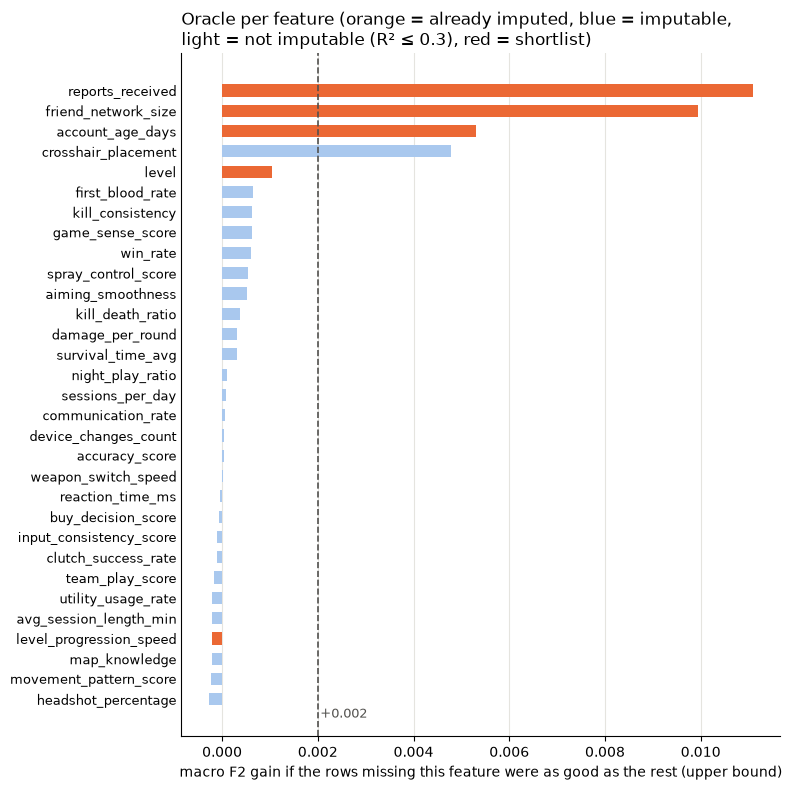

In [13]:
t = table.sort_values('ΔF2')
fig, ax = plt.subplots(figsize=(8, 8))
colours = [RED if s else ORANGE if i == 'yes' else BLUE if imp else '#a9c8ee'
           for s, i, imp in zip(t['shortlist'], t['imputed'], t['imputable'])]
ax.barh(t.index, t['ΔF2'], height=0.6, color=colours)
ax.axvline(0.002, color=INK, linestyle='--', linewidth=1.2)
ax.text(0.00205, -0.9, '+0.002', fontsize=9, color=INK)
ax.set_xlabel('macro F2 gain if the rows missing this feature were as good as the rest (upper bound)')
ax.set_title('Oracle per feature (orange = already imputed, blue = imputable,\nlight = not imputable (R² ≤ 0.3), red = shortlist)', loc='left')
ax.tick_params(axis='y', length=0, labelsize=9)
tidy(ax, 'x')
plt.tight_layout()
plt.show()

**NOTE:**


The shortlist is empty. The 4 features with a real gap are either already imputed (`reports_received`, `friend_network_size`, `account_age_days`) or not imputable (`crosshair_placement`, R² 0.01).

The oracle is still large for the imputed ones (up to +0.011 macro F2 for `reports_received`). Their gap remains after imputation because an imputed value is pulled toward the middle and rarely lands in the range that settles the label. Imputable features without a gap (`level_progression_speed`, the aim block) have an oracle of at most +0.0006.

If every row scored like rows with 0–1 missing, macro F2 would rise by +0.024. That is the full missingness ceiling, but imputation from the other features cannot recover it, because the information is not in them.

### 5b. Can `level` and `level_progression_speed` bound a missing `account_age_days`?

แบบ Task 3 ที่ feature หนึ่งคำนวณจากอีกตัวได้: ถ้า `level_progression_speed` = level / age × u แล้ว u อยู่ในช่วงแคบ ตอน age ว่างก็จะรู้ขอบเขตของ age ได้ และกฎ "age > 1,000 ⇒ ผู้เล่นปกติ" (หรือ age < 15 ⇒ ผู้เล่นปกติ) อาจตัดสินได้เลย ดูว่ามีกี่แถว และโมเดลตอนนี้ทายแถวพวกนั้นถูกอยู่แล้วหรือเปล่า

In [14]:
u = (tr['level_progression_speed'] * tr['account_age_days'] / tr['level']).dropna()  # speed = level / age * u
print(f"u = speed * age / level: min {u.min():.3f}, 1% {u.quantile(0.01):.3f}, median {u.median():.3f}, 99% {u.quantile(0.99):.3f}, max {u.max():.3f} "
      f"| mean legit {u[y[u.index] == 0].mean():.3f}, cheaters {u[y[u.index] == 1].mean():.3f}")
age_gone = tr['account_age_days'].isna() & tr['level'].notna() & tr['level_progression_speed'].notna()
low_bound = u.min() * tr['level'] / tr['level_progression_speed']   # smallest age the other two allow
high_bound = u.max() * tr['level'] / tr['level_progression_speed']  # largest age they allow
rows = []
for name, sel in (('age missing, lower bound > 1,000', age_gone & (low_bound > 1000)),
                  ('age missing, upper bound < 15', age_gone & (high_bound < 15))):
    sel = sel.to_numpy()
    rows.append({'rows': name, 'count': int(sel.sum()), 'cheater share': y[sel].mean(), 'model says cheater': pred[sel].mean(),
                 'rows the model gets wrong': int((pred[sel] != y[sel]).sum())})
print(f"rows missing age: {tr['account_age_days'].isna().sum():,}, of which level and speed are both present: {age_gone.sum():,}")
pd.DataFrame(rows).set_index('rows').style.format({'count': '{:,}', 'cheater share': '{:.1%}', 'model says cheater': '{:.1%}'})

u = speed * age / level: min 0.150, 1% 0.159, median 0.616, 99% 1.071, max 1.080 | mean legit 0.615, cheaters 0.616
rows missing age: 13,141, of which level and speed are both present: 11,199


,count,cheater share,model says cheater,rows the model gets wrong
rows,,,,
"age missing, lower bound > 1,000",24,0.0%,4.2%,1
"age missing, upper bound < 15",114,0.0%,2.6%,3


การเติมค่าเฉลี่ยดึงค่าเข้าหาตรงกลาง จึงไม่ค่อยตกในช่วงที่กฎตัดสินได้ ทางเลือกคือทาย**ความน่าจะเป็นที่ค่าที่ว่างจะข้ามขอบของกฎ** (label-free classifier บนแถวที่มีค่า, 3-fold) ถ้ามีแถวที่ทายได้มั่นใจ (P > 0.9) เยอะ ก็อาจเป็นฟีเจอร์ใหม่ได้

In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict

rule_rows = []
for f, side, v in [('reports_received', '<', 5), ('reports_received', '>', 19), ('friend_network_size', '>', 269),
                   ('account_age_days', '>', 1000), ('crosshair_placement', '<', 0.82), ('crosshair_placement', '>', 0.94),
                   ('level', '<', 28), ('level', '>', 96), ('level_progression_speed', '>', 6.26)]:
    present = tr[f].notna()
    X = tr.loc[present, [c for c in feats if c != f]]  # other features only, never the label
    crosses = (tr.loc[present, f] < v) if side == '<' else (tr.loc[present, f] > v)
    pr = cross_val_predict(HistGradientBoostingClassifier(random_state=342), X, crosses, cv=3, method='predict_proba')[:, 1]
    sure = pr > 0.9
    rule_rows.append({'rule': f"{f} {side} {v}", 'rows crossing (present rows)': crosses.mean(), 'AUC': roc_auc_score(crosses, pr),
                      'rows with P > 0.9': int(sure.sum()), 'precision at P > 0.9': crosses[sure].mean() if sure.any() else np.nan,
                      'gap significant (section 2)': by_feat.loc[f, 'sig_auc'] == 'worse'})
(pd.DataFrame(rule_rows).set_index('rule').style
    .format({'rows crossing (present rows)': '{:.1%}', 'AUC': '{:.3f}', 'rows with P > 0.9': '{:,}', 'precision at P > 0.9': '{:.2f}'}, na_rep='–')
    .set_caption('Label-free: can the other features tell that a hidden value crosses a rule boundary?'))

,rows crossing (present rows),AUC,rows with P > 0.9,precision at P > 0.9,gap significant (section 2)
rule,,,,,
reports_received < 5,2.1%,0.690,0,–,True
reports_received > 19,10.7%,0.873,0,–,True
friend_network_size > 269,5.5%,0.850,0,–,True
account_age_days > 1000,7.3%,0.921,11,1.00,True
crosshair_placement < 0.82,5.0%,0.713,0,–,True
crosshair_placement > 0.94,9.3%,0.613,0,–,True
level < 28,1.4%,0.833,0,–,False
level > 96,3.6%,0.715,0,–,False
level_progression_speed > 6.26,0.7%,0.906,362,0.76,False


**NOTE:**


The data fit speed = level / age × u with u spread evenly over [0.15, 1.08], the same in both classes. So level and speed bound a missing age, but the band is 7× wide. Only 138 of 11,199 such rows fall entirely beyond a rule boundary (all legit), and the model already gets nearly all of them right.

Predicting whether a hidden value crosses a rule boundary works only moderately (AUC 0.61–0.92) and is almost never confident. Apart from 11 rows for `account_age_days` > 1000, the only confident rule is `level_progression_speed` > 6.26, and that feature has no gap when missing. Neither idea leaves anything to gain.

## Summary

- **OOF:** AUC 0.8922 / Macro F2 0.7808 (threshold 0.380) แถวเรียงตรงกับ `train.csv` ต่างจาก README (0.8926 / 0.7807) เพราะสภาพแวดล้อม: สคริปต์ของ README เองรันในเครื่องนี้ก็ได้ 0.8922
- **ค่าว่าง:** แถวครบมีแค่ 1.8% เฉลี่ยว่าง 3.7 ช่องต่อแถว คะแนนตกตามจำนวนช่องที่ว่าง (AUC 0.919 → 0.847, F2 0.809 → 0.743 จาก 0 ถึง 8 ช่อง) สัดส่วนคนโกงเท่ากันทุกกลุ่ม การว่างจึงไม่บอก label
- **Gap ต่อ feature:** significant (Bonferroni) 4 ตัว คือ `reports_received`, `friend_network_size`, `account_age_days`, `crosshair_placement` (z −12 ถึง −21) ทั้ง 4 ตัวเป็น feature ของกฎช่วงค่า ส่วน 25 ตัวที่เหลือว่างแล้วไม่เสียอะไร
- **เติมค่า:** เติมได้แค่บล็อกประวัติบัญชี (age R² 0.71, progression speed 0.63, friends 0.50) ซึ่ง pipeline เติมอยู่แล้ว `crosshair_placement` เติมไม่ได้ (R² 0.01)
- **บล็อก:** มี 2 บล็อก (ประวัติบัญชี, การเล็ง) จาก 465 คู่มีแค่ 8 คู่ที่ |ρ| ≥ 0.2
- **Oracle:** ต่อ feature สูงสุด +0.011 (`reports_received` ที่เติมแล้ว แต่ R² แค่ 0.21) ถ้าทุกแถวดีเท่าแถวที่ว่าง ≤ 1 ช่อง ได้ +0.024 นี่คือขนาดของเพดาน แต่ข้อมูลที่หายไม่ได้อยู่ใน feature อื่น
- **ลองเพิ่ม (5b):** level กับ speed บอกขอบเขตของ age ได้ แต่มีแค่ 138 แถวที่ตัดสินได้และโมเดลทายถูกอยู่แล้ว การทายว่าค่าที่ว่างข้ามขอบกฎไหมก็แทบไม่มีแถวที่มั่นใจ

**Decision: ไม่มีการทดลองเติมค่าเพิ่มสำหรับ Task 1**

| เกณฑ์ | ผล | ผ่านไหม |
|---|---|---|
| OOF แย่ลงจริงในแถวที่ feature ว่าง (Bonferroni) | 4 feature | ผ่าน |
| เติมค่าได้ (R² > 0.3) และยังไม่ได้เติม | ไม่มี: 3 ตัวเติมแล้ว, `reports_received` 0.21, `crosshair_placement` 0.01 | ไม่ผ่าน |
| oracle ของ shortlist > +0.002 Macro F2 | shortlist ว่าง | – |

ค่าว่างเป็นเพดานจริง (+0.024 ถ้าไม่มีค่าว่าง) แต่ส่วนที่เติมจาก feature อื่นได้ pipeline ทำไปแล้ว (เป็นส่วนหนึ่งของ +0.003 เดิม) ที่เหลือคือข้อมูลที่หายไปจริงๆ: feature ที่มีผลที่สุดสัมพันธ์กับตัวอื่นน้อย (`reports_received` R² 0.21, `crosshair_placement` 0.01) ส่วน age ที่เติมได้ดีที่สุดก็ยังมีสัญญาณรบกวนแบบคูณ (u กว้าง 7 เท่า) ต่างจาก Task 3 ที่ feature เกือบเป็นสำเนาของกัน (R² 0.995) จึงไม่ควรลงแรงเรื่องค่าว่างใน Task 1 ต่อ